[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/Quantlets/Ch_18/MFM_ch18_frm/MFM_ch18_frm.ipynb)

# MFM_ch18_frm

Financial Risk Meter for 13 banks: L1-penalized quantile regression at 5% on 63-day windows, penalty chosen by generalized approximate cross-validation (GACV); GACV curves in a calm and a crisis window, the average penalty over time and the share of active predictors (bank and macro) at a fixed penalty.

*Modelling Financial Markets (MFM), Chapter 18: Systemic Risk and Networks. Author: Daniel Traian Pele.*

The penalty is selected from a discrete logarithmic grid; different selected grid points do not by themselves establish a precisely measured difference in risk. Returns enter as fractions without regressor standardisation, so penalty levels depend on the scale of the inputs. The 5% quantile regression uses all 63 observations, but information about the extreme tail is limited. Bank regressors are contemporaneous and market closing times differ; the fitted links describe conditional association, not causal transmission. The FRM–VIX correlation pairs each window's FRM with VIX at its endpoint. Density counts nonzero coefficients among 12 other banks and three lagged market variables for each equation.

For each window, FRM is the arithmetic mean of the 13 bank-specific penalty parameters λ selected by minimizing GACV on the stated grid. When GACV values at several grid points are numerically almost equal, very small numerical differences can change the selected penalty and hence FRM, even when the regression coefficients are almost unchanged. The code selects the grid point with the smallest computed GACV; it does not merge near-ties or impose a tolerance-based choice. Small FRM differences between runs in different computing environments should therefore be interpreted alongside the GACV curves and the scaling of returns and regressors, rather than as precisely measured changes in systemic risk.


> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your ASE Google Drive) and work in that copy.
> For the team project, **File → Save a copy in GitHub** puts the notebook directly in your team's repository.
> Files you create while the notebook runs (CSV, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [ ]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/MFM/Chapter_18'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))


Save your outputs to: /content/mfm-audit/20261017T014312-d65ae3


In [ ]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from scipy.stats import spearmanr
import statsmodels.api as sm
from statsmodels.regression.quantile_regression import QuantReg
from sklearn.linear_model import QuantileRegressor, ElasticNetCV
from scipy import optimize
try:
    from arch import arch_model
except ImportError:                      # Colab: the arch package is not preinstalled
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'arch'])
    from arch import arch_model
import warnings
warnings.filterwarnings('ignore')

## Style and helpers

In [ ]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Course colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Teal     = '#17A2B8'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
REGION_COL = {'US': MainBlue, 'EU': IDAred, 'RO': Forest}
REGION_LAB = {'US': 'US banks', 'EU': 'European banks', 'RO': 'Romanian banks (BVB)'}
EVENTS = [('2011-08-08', 'Euro crisis'), ('2016-06-24', 'Brexit vote'), ('2018-12-19', 'RO bank tax'),
          ('2020-03-16', 'COVID-19'), ('2023-03-13', 'SVB'), ('2025-04-07', 'Tariffs')]

HERE = '.'
FIGURE_OUT_DIR = globals().get('OUT_DIR', '.')
os.makedirs(FIGURE_OUT_DIR, exist_ok=True)
SEED = 42
B_BOOT = 999
RESULTS = {}


def save_fig(name):
    """Save the figure as transparent PDF and PNG in the selected output folder."""
    plt.savefig(os.path.join(FIGURE_OUT_DIR, f'{name}.pdf'), bbox_inches='tight', transparent=True)
    plt.savefig(os.path.join(FIGURE_OUT_DIR, f'{name}.png'), bbox_inches='tight', transparent=True, dpi=180)
    plt.show()
    plt.close()
    print(f"   saved {name}")


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def jsonable(x):
    if isinstance(x, dict):
        return {str(k): jsonable(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [jsonable(v) for v in x]
    if isinstance(x, np.ndarray):
        return [jsonable(v) for v in x.tolist()]
    if isinstance(x, (np.floating, np.integer)):
        return x.item()
    if isinstance(x, pd.Timestamp):
        return str(x.date())
    return x


def mark_events(ax, ymax=None):
    """Vertical reference lines for events, with black labels."""
    for d, lab in EVENTS:
        t = pd.Timestamp(d)
        if ax.get_xlim()[0] <= mdates.date2num(t) <= ax.get_xlim()[1]:
            ax.axvline(t, color=Gray, lw=0.5, ls=':')
            ax.text(t, ax.get_ylim()[1] if ymax is None else ymax, lab, rotation=90, fontsize=6.5, color='black',
                    ha='right', va='top')

## Data

In [ ]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')
START = '2010-01-01'
END = '2026-09-18'

# bank -> (symbol, name, region)
BANKS = {
    'JPM':  ('JPM.US',    'JPMorgan Chase',       'US'),
    'BAC':  ('BAC.US',    'Bank of America',      'US'),
    'C':    ('C.US',      'Citigroup',            'US'),
    'GS':   ('GS.US',     'Goldman Sachs',        'US'),
    'MS':   ('MS.US',     'Morgan Stanley',       'US'),
    'WFC':  ('WFC.US',    'Wells Fargo',          'US'),
    'DBK':  ('DBK.XETRA', 'Deutsche Bank',        'EU'),
    'BNP':  ('BNP.PA',    'BNP Paribas',          'EU'),
    'SAN':  ('SAN.MC',    'Santander',            'EU'),
    'INGA': ('INGA.AS',   'ING',                  'EU'),
    'HSBA': ('HSBA.LSE',  'HSBC',                 'EU'),
    'TLV':  ('TLV.RO',    'Banca Transilvania',   'RO'),
    'BRD':  ('BRD.RO',    'BRD-Groupe SG',        'RO'),
}
US = [k for k, v in BANKS.items() if v[2] == 'US']
EU = [k for k, v in BANKS.items() if v[2] == 'EU']
RO = [k for k, v in BANKS.items() if v[2] == 'RO']
ALL = US + EU + RO
NAMES = {k: v[1] for k, v in BANKS.items()}
INDICES = {'SPX': ('GSPC.INDX', 'S&P 500'), 'SX5E': ('STOXX50E.INDX', 'Euro Stoxx 50'),
           'BET': ('BET', 'BET'), 'VIX': ('VIX.INDX', 'VIX')}
REGION_INDEX = {'US': 'SPX', 'EU': 'SX5E', 'RO': 'BET'}


def read_market(symbol):
    """Read the daily price series of one symbol from the course data."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname)
    src = path if os.path.exists(path) else REPO_RAW + fname
    return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()


def bank_frame(key, start=START, end=END):
    """Daily prices and volume of one bank, with the adjusted price and the corrections above."""
    symbol, _, region = BANKS[key]
    d = read_market(symbol).loc[start:end].copy()
    d = d[(d.index.dayofweek < 5) & (d['adjusted_close'] > 0)]
    if region == 'RO':
        d = d[d['volume'] > 0]                                   # days without trades
    if key == 'TLV' and pd.Timestamp('2016-05-30') in d.index:
        # bonus-share adjustment: the post-ex-date factor also applies on 30 May 2016
        f = d.loc['2016-05-31', 'adjusted_close'] / d.loc['2016-05-31', 'close']
        d.loc['2016-05-30', 'adjusted_close'] = d.loc['2016-05-30', 'close'] * f
    return d


def bank_price(key, start=START, end=END):
    return bank_frame(key, start, end)['adjusted_close'].rename(key)


def index_close(key, start=START, end=END):
    s = read_market(INDICES[key][0])['close'].loc[start:end]
    s = s[(s.index.dayofweek < 5) & (s > 0)].dropna()
    if key != 'VIX':
        s = s[s.diff() != 0]                                     # holidays filled with the previous price
    return s.rename(key)


def prices(keys, start=START, end=END):
    """Daily prices of banks and/or indices, on common trading days only."""
    cols = [bank_price(k, start, end) if k in BANKS else index_close(k, start, end) for k in keys]
    return pd.concat(cols, axis=1, join='inner').dropna()


def joint_returns(keys, start=START, end=END):
    """Daily log returns in %: prices are aligned on common trading days first, then returns are computed."""
    return 100 * np.log(prices(keys, start, end)).diff().dropna()


def bank_range_vol(keys, start=START, end=END):
    """Daily Parkinson volatility (in %, annualised), on the days common to all banks."""
    out = []
    for k in keys:
        d = bank_frame(k, start, end)
        rng = np.log(d['high'] / d['low']).where(d['high'] > d['low'])
        s2 = rng ** 2 / (4 * np.log(2))
        floor = s2.where(s2 > 0).cummin().ffill()                  # smallest positive value observed UP TO day t
        s2 = s2.fillna(floor)                                     # days with high = low: no look-ahead bias
        out.append((100 * np.sqrt(252 * s2)).rename(k))
    return pd.concat(out, axis=1, join='inner').dropna()


def system_return(R, members):
    """System return: equal-weighted portfolio of the banks (log returns in %, daily approximation)."""
    return R[members].mean(axis=1)


# daily log returns in % (common days) and log Parkinson volatility
R = joint_returns(ALL + ['SPX', 'SX5E', 'BET', 'VIX'])
V = np.log(bank_range_vol(ALL))
print(R.index[0].date(), '->', R.index[-1].date(), len(R), 'common days')


def system_ex(k, members):
    """Return of the regional system without bank k (equal-weighted portfolio)."""
    return R[[j for j in members if j != k]].mean(axis=1)


def region_of(k):
    return BANKS[k][2]

2010-01-05 -> 2026-09-18 3960 common days


## Systemic risk measures

In [ ]:
def mes(r_i, r_m, alpha=0.05):
    """MES (%): average loss of the bank on the days when the market is in its alpha-probability tail."""
    q = np.quantile(r_m, alpha)
    return -np.mean(np.asarray(r_i)[np.asarray(r_m) <= q])


def mes_threshold(r_i, r_m, c=-2.0):
    """MES (%) on the days when the market falls by more than |c|% (the definition used for LRMES)."""
    return -np.mean(np.asarray(r_i)[np.asarray(r_m) < c])


def lrmes(mes2_pct):
    """Long-run loss in a crisis (market -40% over six months): LRMES = 1 - exp(-18 MES), MES as a fraction."""
    return 1 - np.exp(-18 * mes2_pct / 100)


def srisk_ratio(lrm, leverage, k=0.08):
    """SRISK / market equity W: k(L - 1) - (1 - k)(1 - LRMES), with L = (D + W)/W."""
    return k * (leverage - 1) - (1 - k) * (1 - lrm)


def breakeven_leverage(lrm, k=0.08):
    """Leverage L* above which SRISK > 0: L* = 1 + (1 - k)(1 - LRMES)/k."""
    return 1 + (1 - k) * (1 - lrm) / k


def qreg(y, X, q):
    """Quantile regression (Koenker-Bassett); returns the coefficients [intercept, slopes]."""
    return QuantReg(np.asarray(y), sm.add_constant(np.asarray(X), has_constant='add')).fit(q=q, max_iter=5000).params


def covar_static(x_sys, x_i, alpha=0.01):
    """Unconditional CoVaR and Delta-CoVaR (%, positive = losses).

    Quantile regression at level alpha: X_sys = a + b X_i;
    CoVaR_alpha = -(a + b q_alpha(X_i)); Delta-CoVaR = b (q_50(X_i) - q_alpha(X_i))."""
    x_sys, x_i = np.asarray(x_sys), np.asarray(x_i)
    a, b = qreg(x_sys, x_i, alpha)
    qa, qm = np.quantile(x_i, alpha), np.quantile(x_i, 0.5)
    return {'a': a, 'b': b, 'var_i': -qa, 'covar': -(a + b * qa), 'covar_med': -(a + b * qm),
            'dcovar': b * (qm - qa), 'var_sys': -np.quantile(x_sys, alpha)}


def block_bootstrap_idx(n, block=20, rng=None):
    """Indices for the moving-block bootstrap (Künsch), fixed-length blocks."""
    rng = rng or np.random.default_rng(0)
    starts = rng.integers(0, n - block + 1, size=int(np.ceil(n / block)))
    return (starts[:, None] + np.arange(block)[None, :]).ravel()[:n]


def covar_boot(x_sys, x_i, alpha=0.01, B=200, block=20, seed=0):
    """95% percentile interval for Delta-CoVaR by moving-block bootstrap."""
    x_sys, x_i = np.asarray(x_sys), np.asarray(x_i)
    rng = np.random.default_rng(seed)
    d = []
    for _ in range(B):
        idx = block_bootstrap_idx(len(x_i), block, rng)
        d.append(covar_static(x_sys[idx], x_i[idx], alpha)['dcovar'])
    return np.percentile(d, [2.5, 97.5])


def covar_dynamic(x_sys, x_i, M, alpha=0.01):
    """Time-varying Delta-CoVaR with state variables M_{t-1} (Adrian & Brunnermeier, 2016).

    X_i,t = a + c'M_{t-1} at levels alpha and 50%  ->  VaR_i,t;
    X_sys,t = a + b X_i,t + c'M_{t-1} at level alpha  ->  Delta-CoVaR_t = b (q50_i,t - qalpha_i,t)."""
    ci_a = qreg(x_i, M, alpha)
    ci_m = qreg(x_i, M, 0.5)
    cs = qreg(x_sys, np.column_stack([x_i, M]), alpha)
    Mc = sm.add_constant(np.asarray(M), has_constant='add')
    qa, qm = Mc @ ci_a, Mc @ ci_m
    return pd.DataFrame({'var_i': -qa, 'dcovar': cs[1] * (qm - qa)}, index=getattr(x_i, 'index', None)), cs[1]


def var_fit(Y, p):
    """VAR(p) estimated by OLS; returns the coefficients A_1..A_p (k x k) and the residual covariance matrix."""
    Y = np.asarray(Y, float)
    T, k = Y.shape
    X = np.hstack([np.ones((T - p, 1))] + [Y[p - l - 1:T - l - 1] for l in range(p)])
    Yt = Y[p:]
    B = np.linalg.lstsq(X, Yt, rcond=None)[0]
    E = Yt - X @ B
    S = E.T @ E / (len(Yt) - X.shape[1])
    A = [B[1 + l * k:1 + (l + 1) * k].T for l in range(p)]
    return A, S


def var_bic(Y, pmax=5):
    """VAR order chosen by the Bayesian information criterion (BIC, Schwarz), with the maximum-likelihood residual covariance matrix."""
    Y = np.asarray(Y, float)
    T, k = Y.shape
    best = None
    n = T - pmax
    for p in range(1, pmax + 1):
        A, S = var_fit(Y[pmax - p:], p)
        S_ml = S * (n - 1 - p * k) / n                        # maximum-likelihood covariance E'E / n
        bic = np.log(np.linalg.det(S_ml)) + np.log(n) * p * k * k / n
        if best is None or bic < best[1]:
            best = (p, bic)
    return best[0]


def ma_coefs(A, H):
    """Moving-average coefficients Phi_0..Phi_{H-1}."""
    k = A[0].shape[0]
    Phi = [np.eye(k)]
    for h in range(1, H):
        Phi.append(sum(A[l] @ Phi[h - l - 1] for l in range(min(h, len(A)))))
    return Phi


def gfevd(A, S, H=10):
    """Generalized forecast error variance decomposition (Pesaran-Shin), rows normalised."""
    Phi = ma_coefs(A, H)
    k = S.shape[0]
    num = np.zeros((k, k))
    den = np.zeros(k)
    for P in Phi:
        PS = P @ S
        num += PS ** 2
        den += np.diag(P @ S @ P.T)
    theta = num / np.diag(S)[None, :] / den[:, None]
    return theta / theta.sum(axis=1, keepdims=True)


def spillover_table(theta, names):
    """Connectedness table: contributions (%), FROM, TO, NET and the total index."""
    k = theta.shape[0]
    D = 100 * theta
    off = D - np.diag(np.diag(D))
    frm, to = off.sum(axis=1), off.sum(axis=0)
    tab = pd.DataFrame(D, index=names, columns=names)
    return {'table': tab, 'from': pd.Series(frm, index=names), 'to': pd.Series(to, index=names),
            'net': pd.Series(to - frm, index=names), 'total': off.sum() / k,
            'pairwise_net': pd.DataFrame(off.T - off, index=names, columns=names)}


def rolling_total(Y, window=250, step=5, p=2, H=10):
    """Total connectedness index on rolling windows."""
    Y = pd.DataFrame(Y)
    out, frm_to = {}, {}
    for end in range(window, len(Y) + 1, step):
        w = Y.iloc[end - window:end]
        A, S = var_fit(w.values, p)
        st = spillover_table(gfevd(A, S, H), list(Y.columns))
        out[Y.index[end - 1]] = st['total']
        frm_to[Y.index[end - 1]] = st['net']
    return pd.Series(out), pd.DataFrame(frm_to).T


def check_loss(u, tau):
    return u * (tau - (u < 0))


def lasso_qr_gacv(y, X, tau=0.05, lambdas=None):
    """L1-penalized quantile regression; lambda chosen by the generalized approximate cross-validation criterion GACV = sum rho_tau(res) / (n - df)."""
    y, X = np.asarray(y, float), np.asarray(X, float)
    n = len(y)
    lambdas = np.logspace(-4, -0.5, 15) if lambdas is None else lambdas
    rows = []
    for lam in lambdas:
        m = QuantileRegressor(quantile=tau, alpha=lam, solver='highs').fit(X, y)
        res = y - m.predict(X)
        df = int(np.sum(np.abs(m.coef_) > 1e-8))
        g = check_loss(res, tau).sum() / max(n - df, 1)
        rows.append((lam, g, df, m.coef_.copy()))
    i = int(np.argmin([r[1] for r in rows]))
    return {'lambda': rows[i][0], 'gacv': [r[1] for r in rows], 'df': [r[2] for r in rows],
            'lambdas': list(lambdas), 'coef': rows[i][3], 'df_sel': rows[i][2]}

## Helper functions

In [ ]:
MACRO = ['SPX', 'SX5E', 'VIX']

LAMBDAS = np.logspace(-6, -1.5, 20)

## Analysis

In [ ]:
def frm_design():
    """Daily returns (fractions) of the banks and the macro variables lagged by one day."""
    Rf = R / 100
    Mac = Rf[MACRO].shift(1).add_suffix('_lag')
    return Rf[ALL].join(Mac).dropna()


def frm_window(D, k, tau=0.05):
    X = D[[j for j in ALL if j != k] + [c for c in D.columns if c.endswith('_lag')]]
    return lasso_qr_gacv(D[k].values, X.values, tau, LAMBDAS)


def frm_series(window=63, step=10, lam_fixed=2e-4):
    """FRM = average lambda (GACV) across banks, on rolling 63-day windows; and the share of active predictors
    (12 banks + 3 lagged macro variables) at a fixed lambda."""
    D = frm_design()
    rows = {}
    cache = os.path.join(HERE, 'ch18_frm.csv')
    if os.environ.get('MFM_FRM_CACHE') and os.path.exists(cache):
        return pd.read_csv(cache, index_col=0, parse_dates=True), LAMBDAS[int(np.argmin(np.abs(LAMBDAS - lam_fixed)))]
    j_fix = int(np.argmin(np.abs(LAMBDAS - lam_fixed)))
    for end in range(window, len(D) + 1, step):
        w = D.iloc[end - window:end]
        lam, dens = [], []
        for k in ALL:
            r = frm_window(w, k)
            lam.append(r['lambda'])
            dens.append(r['df'][j_fix] / (len(ALL) - 1 + len(MACRO)))
        rows[D.index[end - 1]] = {'frm': np.mean(lam), 'density': np.mean(dens)}
    f = pd.DataFrame(rows).T
    f.to_csv(os.path.join(HERE, 'ch18_frm.csv'))
    return f, LAMBDAS[j_fix]


def fig_frm_gacv():
    """GACV curve for JPMorgan in a calm and in a crisis window."""
    D = frm_design()
    out = {}
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.8))
    for ax, (end, lab, c) in zip(axes, [('2019-06-28', 'Calm window ending 28 Jun 2019', MainBlue),
                                        ('2020-03-31', 'COVID-19 window ending 31 Mar 2020', IDAred)]):
        w = D.loc[:end].iloc[-63:]
        r = frm_window(w, 'JPM')
        ax.plot(LAMBDAS, 1e3 * np.array(r['gacv']), 'o-', color=c, ms=3, lw=1, label=lab)
        ax.axvline(r['lambda'], color=Gray, lw=0.6, ls=':')
        ax.set_xscale('log')
        ax.set_xlabel('Penalty λ')
        ax.set_ylabel('GACV(λ) × 1000')
        ax2 = ax.twinx()
        ax2.step(LAMBDAS, r['df'], where='mid', color=Orange, lw=0.9, label='Active coefficients')
        ax2.set_ylabel('Active coefficients')
        ax2.spines['right'].set_visible(True)
        h = ax.get_lines()[:1] + ax2.get_lines()[:1]
        ax.legend(h, [l.get_label() for l in h], loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=1, frameon=False)
        out[end] = {'lambda': r['lambda'], 'df': r['df_sel'], 'gacv_min': min(r['gacv'])}
    fig.tight_layout()
    save_fig('ch18_frm_gacv')
    return out


def fig_frm_rolling(f, lam_fix):
    vix = index_close('VIX').reindex(f.index)
    fig, axes = plt.subplots(2, 1, figsize=(7.2, 4.4), sharex=True)
    axes[0].plot(f.index, 1e4 * f['frm'], color=MainBlue, lw=0.9, label='FRM: average GACV penalty λ × 10,000 (13 banks)')
    axes[0].set_ylabel('λ × 10,000')
    axes[1].plot(f.index, 100 * f['density'], color=Purple, lw=0.9,
                 label=f'Share of active predictors (12 banks + 3 lagged macro variables) at a fixed penalty λ = {lam_fix:.1e}')
    axes[1].set_ylabel('Active predictors (%)')
    ax3 = axes[1].twinx()
    ax3.plot(vix.index, vix.values, color=Orange, lw=0.7, label='VIX (right axis)')
    ax3.spines['right'].set_visible(True)
    ax3.set_ylabel('VIX')
    axes[0].set_xlim(f.index[0], f.index[-1])
    mark_events(axes[0])
    fig.tight_layout()
    h = axes[0].get_lines()[:1] + axes[1].get_lines()[:1] + ax3.get_lines()[:1]
    fig.legend(h, [l.get_label() for l in h], loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=1, frameon=False)
    save_fig('ch18_frm_rolling')
    return {'corr_frm_vix': f['frm'].corr(vix), 'corr_dens_vix': f['density'].corr(vix),
            'frm_mean': f['frm'].mean(), 'dens_mean': f['density'].mean(),
            'dens_max': f['density'].max(), 'dens_max_date': f['density'].idxmax(),
            'dens_min': f['density'].min(), 'dens_min_date': f['density'].idxmin(), 'n_windows': len(f)}

## Run

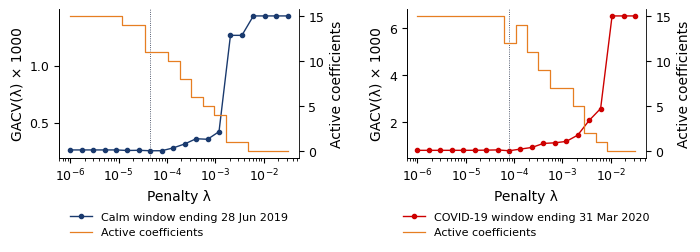

   saved ch18_frm_gacv
{'2019-06-28': {'lambda': np.float64(4.548777947003778e-05), 'df': 11, 'gacv_min': np.float64(0.00025399989976129794)}, '2020-03-31': {'lambda': np.float64(7.847599703514606e-05), 'df': 12, 'gacv_min': np.float64(0.0007708372919225474)}}


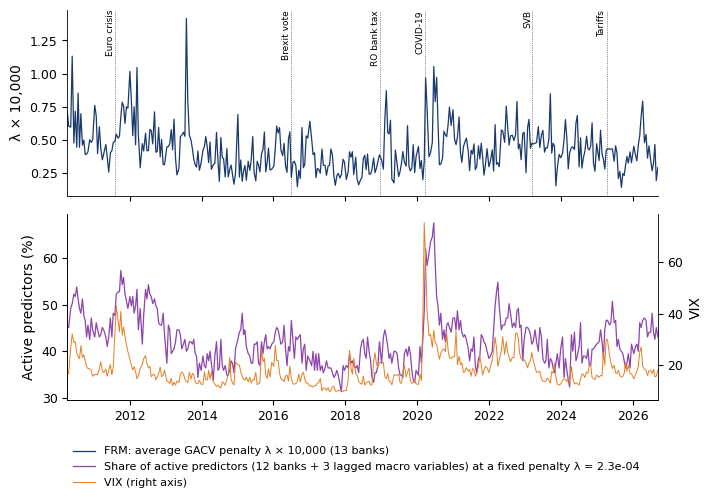

   saved ch18_frm_rolling
{'corr_frm_vix': np.float64(0.3501307890826868), 'corr_dens_vix': np.float64(0.6199655732817195), 'frm_mean': np.float64(4.318485465414981e-05), 'dens_mean': np.float64(0.4244444444444445), 'dens_max': 0.6769230769230768, 'dens_max_date': Timestamp('2020-06-17 00:00:00'), 'dens_min': 0.3128205128205129, 'dens_min_date': Timestamp('2017-11-21 00:00:00'), 'n_windows': 390}


In [ ]:
print(fig_frm_gacv())
f, lam_fix = frm_series()   # 390 windows x 13 banks: a few minutes
print(fig_frm_rolling(f, lam_fix))

![ch18_frm_gacv](./ch18_frm_gacv.png)

Output: `ch18_frm_gacv.pdf`

![ch18_frm_rolling](./ch18_frm_rolling.png)

Output: `ch18_frm_rolling.pdf`